In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, glob, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models

DATA_DIR = "/content/drive/MyDrive/PQ_Dataset"
OUTPUT_DIR = "/content/drive/MyDrive/PQ_Dataset/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
ABLATION_FOLDS = 3        # set to 5 for the full protocol (slower)
EPOCHS = 40

COMPOUND_CLASSES = {
    "Flicker_with_Sag", "Flicker_with_Swell", "Harmonics_with_Sag",
    "Harmonics_with_Swell", "Sag_with_Harmonics", "Sag_with_Oscillatory_Transient",
    "Swell_with_Harmonics", "Swell_with_Oscillatory_Transient",
}

def set_seed(s=RANDOM_STATE):
    np.random.seed(s); random.seed(s); tf.random.set_seed(s)
set_seed()
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

In [3]:
signals, labels = [], []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    label = os.path.splitext(os.path.basename(path))[0]
    data = pd.read_csv(path, header=None)
    signals.append(data.values.astype(np.float32))
    labels.extend([label] * len(data))

X_raw = np.vstack(signals)
y = np.array(labels)
classes = sorted(np.unique(y))
is_compound = np.array([c in COMPOUND_CLASSES for c in classes])
y_enc = LabelEncoder().fit(classes).transform(y)
N_SAMPLES = X_raw.shape[1]

# Per-signal z-score version, used only by the "input normalisation" variant
X_norm = (X_raw - X_raw.mean(axis=1, keepdims=True)) / (X_raw.std(axis=1, keepdims=True) + 1e-8)

# The 80% pool. The 20% test set is NOT used anywhere in this notebook.
tv_path = f"{OUTPUT_DIR}/trainval_idx.npy"
if os.path.exists(tv_path):
    trainval_idx = np.load(tv_path)
    print("Loaded saved train+validation indices")
else:
    trainval_idx, _ = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                       random_state=RANDOM_STATE, stratify=y)
    print("Recreated the same 80/20 split")
print(f"{len(classes)} classes | pool for ablation: {len(trainval_idx)} signals")


Loaded saved train+validation indices
17 classes | pool for ablation: 13600 signals


In [4]:
def get_optimizer(name, lr):
    if name == "adam":    return tf.keras.optimizers.Adam(learning_rate=lr)
    if name == "rmsprop": return tf.keras.optimizers.RMSprop(learning_rate=lr)
    if name == "sgd":     return tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    raise ValueError(name)

def build_model(n_classes, n_samples,
                use_batchnorm=True, use_dropout=True, dropout_rate=0.3,
                n_conv_blocks=3, filters=(32, 64, 128), kernel_sizes=(5, 5, 3),
                use_maxpool=True, pooling="gap", dense_units=64,
                activation="relu", optimizer="adam", lr=0.0005):
    x_in = layers.Input(shape=(n_samples, 1))
    x = x_in
    for i in range(n_conv_blocks):
        x = layers.Conv1D(filters[i], kernel_size=kernel_sizes[i], activation=activation, padding="same")(x)
        if use_batchnorm:
            x = layers.BatchNormalization()(x)
        if use_maxpool and i < n_conv_blocks - 1:
            x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.GlobalAveragePooling1D()(x) if pooling == "gap" else layers.Flatten()(x)
    if dense_units > 0:
        x = layers.Dense(dense_units, activation=activation)(x)
    if use_dropout:
        x = layers.Dropout(dropout_rate)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = models.Model(x_in, out)
    m.compile(optimizer=get_optimizer(optimizer, lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ]

In [5]:
# name -> (group, model kwargs, extra options)  extra: batch_size, normalize_input
EXPERIMENTS = {
    "Baseline (full model)":     ("Baseline", {}, {}),

    # --- Removal: take a component out ---
    "No BatchNorm":              ("Removal", dict(use_batchnorm=False), {}),
    "No Dropout":                ("Removal", dict(use_dropout=False), {}),
    "No MaxPooling":             ("Removal", dict(use_maxpool=False), {}),
    "No hidden dense layer":     ("Removal", dict(dense_units=0), {}),
    "2 conv blocks (not 3)":     ("Removal", dict(n_conv_blocks=2), {}),
    "1 conv block (not 3)":      ("Removal", dict(n_conv_blocks=1), {}),

    # --- Change: swap a setting ---
    "Flatten instead of GAP":    ("Change", dict(pooling="flatten"), {}),
    "Kernel size 3 everywhere":  ("Change", dict(kernel_sizes=(3, 3, 3)), {}),
    "Kernel size 7 everywhere":  ("Change", dict(kernel_sizes=(7, 7, 7)), {}),
    "Fewer filters (16/32/64)":  ("Change", dict(filters=(16, 32, 64)), {}),
    "More filters (64/128/256)": ("Change", dict(filters=(64, 128, 256)), {}),
    "Dense 32":                  ("Change", dict(dense_units=32), {}),
    "Dense 128":                 ("Change", dict(dense_units=128), {}),
    "Dropout 0.1":               ("Change", dict(dropout_rate=0.1), {}),
    "Dropout 0.5":               ("Change", dict(dropout_rate=0.5), {}),
    "Activation tanh":           ("Change", dict(activation="tanh"), {}),
    "Learning rate 0.0001":      ("Change", dict(lr=0.0001), {}),
    "Learning rate 0.005":       ("Change", dict(lr=0.005), {}),
    "Optimizer RMSprop":         ("Change", dict(optimizer="rmsprop"), {}),
    "Batch size 16":             ("Change", {}, dict(batch_size=16)),
    "Batch size 128":            ("Change", {}, dict(batch_size=128)),

    # --- Addition: add a component ---
    "Per-signal z-score input":  ("Addition", {}, dict(normalize_input=True)),
}
print(len(EXPERIMENTS), "experiments x", ABLATION_FOLDS, "folds =", len(EXPERIMENTS) * ABLATION_FOLDS, "training runs")

23 experiments x 3 folds = 69 training runs


In [6]:
def run_experiment(kwargs, extra):
    X = (X_norm if extra.get("normalize_input") else X_raw).reshape(-1, N_SAMPLES, 1)
    bs = extra.get("batch_size", 32)
    skf = StratifiedKFold(n_splits=ABLATION_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    accs, f1s, n_params = [], [], None
    for tr, va in skf.split(trainval_idx, y[trainval_idx]):
        tr_idx, va_idx = trainval_idx[tr], trainval_idx[va]
        fit_idx, es_idx = train_test_split(tr_idx, test_size=0.15, random_state=RANDOM_STATE,
                                           stratify=y[tr_idx])       # inner split for early stopping
        tf.keras.backend.clear_session(); set_seed()
        m = build_model(len(classes), N_SAMPLES, **kwargs)
        n_params = m.count_params()
        m.fit(X[fit_idx], y_enc[fit_idx], validation_data=(X[es_idx], y_enc[es_idx]),
              epochs=EPOCHS, batch_size=bs, callbacks=make_callbacks(), verbose=0)
        pred = np.argmax(m.predict(X[va_idx], verbose=0), axis=1)
        accs.append(accuracy_score(y_enc[va_idx], pred) * 100)
        f1s.append(f1_score(y_enc[va_idx], pred, labels=range(len(classes)), average=None, zero_division=0))
    return np.array(accs), np.array(f1s).mean(axis=0), n_params

rows = []
for name, (group, kwargs, extra) in EXPERIMENTS.items():
    t0 = time.time()
    accs, mf1, n_params = run_experiment(kwargs, extra)
    rows.append({
        "variant": name, "group": group,
        "val_acc_mean": accs.mean(), "val_acc_std": accs.std(),
        "non_compound_f1": mf1[~is_compound].mean(), "compound_f1": mf1[is_compound].mean(),
        "n_params": n_params,
    })
    print(f"{name:<28} val acc {accs.mean():6.2f}% +/- {accs.std():.2f}   ({time.time()-t0:.0f}s)")
    pd.DataFrame(rows).to_csv(f"{OUTPUT_DIR}/ablation_validation_results.csv", index=False)  # saved as it goes

Baseline (full model)        val acc  94.29% +/- 0.11   (357s)
No BatchNorm                 val acc  86.82% +/- 2.95   (270s)
No Dropout                   val acc  94.14% +/- 0.46   (348s)
No MaxPooling                val acc  94.46% +/- 0.26   (346s)
No hidden dense layer        val acc  94.15% +/- 0.97   (326s)
2 conv blocks (not 3)        val acc  87.90% +/- 0.89   (300s)
1 conv block (not 3)         val acc  64.57% +/- 0.68   (240s)
Flatten instead of GAP       val acc  92.26% +/- 0.70   (339s)
Kernel size 3 everywhere     val acc  95.42% +/- 0.46   (345s)
Kernel size 7 everywhere     val acc  94.38% +/- 0.34   (353s)
Fewer filters (16/32/64)     val acc  92.38% +/- 0.42   (345s)
More filters (64/128/256)    val acc  96.08% +/- 0.10   (454s)
Dense 32                     val acc  93.87% +/- 0.38   (359s)
Dense 128                    val acc  91.50% +/- 3.68   (297s)
Dropout 0.1                  val acc  94.54% +/- 0.41   (367s)
Dropout 0.5                  val acc  93.71% +/- 0.76  

In [7]:
res = pd.DataFrame(rows)
base = res.loc[res.variant == "Baseline (full model)", "val_acc_mean"].iloc[0]
res["change_vs_baseline"] = res["val_acc_mean"] - base
res["gap_noncomp_minus_comp"] = res["non_compound_f1"] - res["compound_f1"]
res.to_csv(f"{OUTPUT_DIR}/ablation_validation_results.csv", index=False)

show = res.sort_values("val_acc_mean", ascending=False)[
    ["variant", "group", "val_acc_mean", "val_acc_std", "change_vs_baseline", "compound_f1", "n_params"]]
print(f"Baseline validation accuracy: {base:.2f}%\n")
print(show.round(3).to_string(index=False))

Baseline validation accuracy: 94.29%

                  variant    group  val_acc_mean  val_acc_std  change_vs_baseline  compound_f1  n_params
More filters (64/128/256)   Change        96.081        0.099               1.794        0.956    159377
 Kernel size 3 everywhere   Change        95.419        0.464               1.132        0.946     41297
      Learning rate 0.005   Change        95.162        0.175               0.875        0.950     45457
            Batch size 16   Change        94.684        0.562               0.397        0.943     45457
              Dropout 0.1   Change        94.537        0.407               0.250        0.943     45457
        Optimizer RMSprop   Change        94.471        0.635               0.184        0.939     45457
            No MaxPooling  Removal        94.456        0.255               0.169        0.940     45457
 Kernel size 7 everywhere   Change        94.382        0.344               0.096        0.936     82385
    Baseline (ful

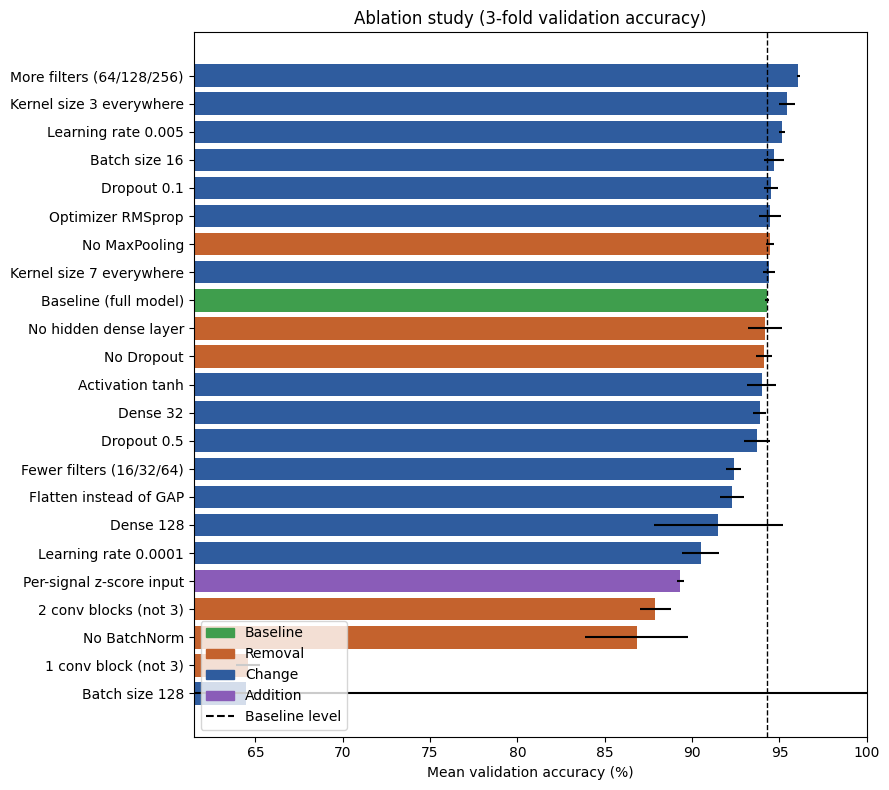

In [8]:
colors = {"Baseline": "#3F9E4D", "Removal": "#C4622D", "Change": "#2F5C9E", "Addition": "#8A5CB8"}
plot_df = res.sort_values("val_acc_mean")
plt.figure(figsize=(9, 8))
plt.barh(plot_df["variant"], plot_df["val_acc_mean"], xerr=plot_df["val_acc_std"],
         color=[colors[g] for g in plot_df["group"]])
plt.axvline(base, color="k", linestyle="--", linewidth=1, label=f"Baseline {base:.2f}%")
plt.xlim(max(0, plot_df["val_acc_mean"].min() - 3), 100)
plt.xlabel("Mean validation accuracy (%)")
plt.title(f"Ablation study ({ABLATION_FOLDS}-fold validation accuracy)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
plt.legend(handles + [plt.Line2D([0], [0], color="k", linestyle="--")],
           list(colors.keys()) + ["Baseline level"], loc="lower left")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/ablation_validation.png", dpi=150); plt.show()